In [19]:
%pip install tensorflow

  Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl.metadata (4.5 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached grpcio-1.84.1-cp313-cp313-win_amd64.whl.metadata (3.9 kB)
  Using cached keras-3.15.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached ml_dtypes-0.6.0-cp313-cp313-win_amd64.whl.metadata (8.8 kB)
  Using cached namex-0.1.0-py3-none-any.whl.metadata (322 bytes)
  Using cached opt

ERROR: Could not install packages due to an OSError: [WinError 32] The process cannot access the file because it is being used by another process: 'C:\\Users\\vijay\\AppData\\Local\\Temp\\pip-unpack-kuy4dgmt\\tensorflow-2.21.0-cp313-cp313-win_amd64.whl'
Consider using the `--user` option or check the permissions.



In [ ]:
import re
import nltk
import matplotlib.pyplot as plt

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

stop_words = set(stopwords.words('english'))

Original Text:
 
Artificial intelligence is transforming modern technology.
It helps people solve complex problems quickly.
Machine learning allows computers to learn from data.
AI applications are useful in education, healthcare, and business.
I enjoy learning artificial intelligence because it encourages creativity.
In the future, intelligent systems may improve everyday life.


Cleaned Text:
 
artificial intelligence is transforming modern technology
it helps people solve complex problems quickly
machine learning allows computers to learn from data
ai applications are useful in education healthcare and business
i enjoy learning artificial intelligence because it encourages creativity
in the future intelligent systems may improve everyday life


Word Tokens: ['artificial', 'intelligence', 'is', 'transforming', 'modern', 'technology', 'it', 'helps', 'people', 'solve', 'complex', 'problems', 'quickly', 'machine', 'learning', 'allows', 'computers', 'to', 'learn', 'from', 'data', 'ai', '

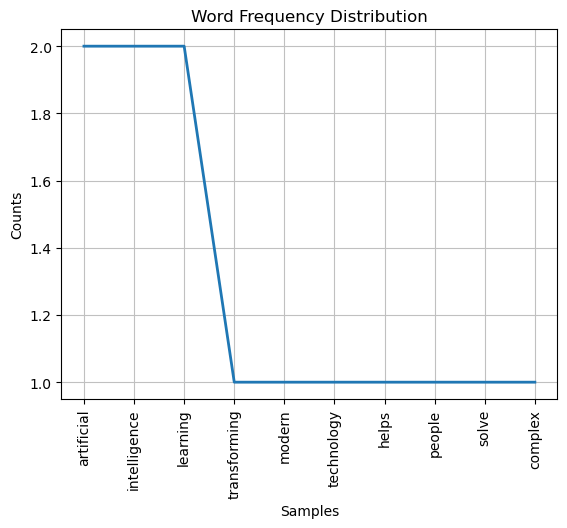

In [22]:

text = """
Artificial intelligence is transforming modern technology.
It helps people solve complex problems quickly.
Machine learning allows computers to learn from data.
AI applications are useful in education, healthcare, and business.
I enjoy learning artificial intelligence because it encourages creativity.
In the future, intelligent systems may improve everyday life.
"""

clean_text = re.sub(r'[^\w\s]', '', text.lower())

print("Original Text:\n", text)
print("\nCleaned Text:\n", clean_text)

words = word_tokenize(clean_text)
sentences = sent_tokenize(text)

print("\nWord Tokens:", words)
print("\nSentence Tokens:", sentences)

print("\nUsing split():", clean_text.split())
print("\nUsing word_tokenize():", word_tokenize(text.lower()))

filtered_words = [
    word for word in words
    if word not in stop_words and word.isalpha()
]

print("\nWords after Stopword Removal:", filtered_words)

frequency = FreqDist(filtered_words)

print("\nWord Frequencies:")
print(frequency.most_common())

frequency.plot(10, title="Word Frequency Distribution")
plt.show()

In [23]:

from nltk.stem import PorterStemmer, WordNetLemmatizer

text2 = """Artificial intelligence helps computers understand information.
Students are learning new technologies and building useful applications.
These systems process data, solve problems, and improve services."""

alpha_words = re.findall(r'\b[a-zA-Z]+\b', text2.lower())
filtered = [w for w in alpha_words if w not in stop_words]

stemmer = PorterStemmer()
stemmed = [stemmer.stem(w) for w in filtered]

lemmatizer = WordNetLemmatizer()
lemmatized = [lemmatizer.lemmatize(w) for w in filtered]

print("Alphabetic Words:", alpha_words)
print("After Stopword Removal:", filtered)
print("Stemmed Words:", stemmed)
print("Lemmatized Words:", lemmatized)

for w, s, l in zip(filtered, stemmed, lemmatized):
    print(w, "-> Stem:", s, "| Lemma:", l)

Alphabetic Words: ['artificial', 'intelligence', 'helps', 'computers', 'understand', 'information', 'students', 'are', 'learning', 'new', 'technologies', 'and', 'building', 'useful', 'applications', 'these', 'systems', 'process', 'data', 'solve', 'problems', 'and', 'improve', 'services']
After Stopword Removal: ['artificial', 'intelligence', 'helps', 'computers', 'understand', 'information', 'students', 'learning', 'new', 'technologies', 'building', 'useful', 'applications', 'systems', 'process', 'data', 'solve', 'problems', 'improve', 'services']
Stemmed Words: ['artifici', 'intellig', 'help', 'comput', 'understand', 'inform', 'student', 'learn', 'new', 'technolog', 'build', 'use', 'applic', 'system', 'process', 'data', 'solv', 'problem', 'improv', 'servic']
Lemmatized Words: ['artificial', 'intelligence', 'help', 'computer', 'understand', 'information', 'student', 'learning', 'new', 'technology', 'building', 'useful', 'application', 'system', 'process', 'data', 'solve', 'problem', 'i

In [24]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd


texts = [
    "Artificial intelligence improves healthcare and education.",
    "Machine learning helps computers analyze data and make predictions.",
    "Blockchain provides secure and transparent digital transactions."
]



cv = CountVectorizer()
bow = cv.fit_transform(texts)

print("Bag of Words:")
print(pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out()))

tfidf = TfidfVectorizer(stop_words='english')
matrix = tfidf.fit_transform(texts)
features = tfidf.get_feature_names_out()

print("TF-IDF Scores:")
print(pd.DataFrame(matrix.toarray(), columns=features).round(3))

for i, row in enumerate(matrix.toarray()):
    top = row.argsort()[-3:][::-1]
    print(f"\nText {i+1} Top 3 Keywords:")
    for idx in top:
        print(features[idx], round(row[idx], 3))

Bag of Words:
   analyze  and  artificial  blockchain  computers  data  digital  education  \
0        0    1           1           0          0     0        0          1   
1        1    1           0           0          1     1        0          0   
2        0    1           0           1          0     0        1          0   

   healthcare  helps  improves  intelligence  learning  machine  make  \
0           1      0         1             1         0        0     0   
1           0      1         0             0         1        1     1   
2           0      0         0             0         0        0     0   

   predictions  provides  secure  transactions  transparent  
0            0         0       0             0            0  
1            1         0       0             0            0  
2            0         1       1             1            1  
TF-IDF Scores:
   analyze  artificial  blockchain  computers   data  digital  education  \
0    0.000       0.447       0.00

In [31]:
%pip install textblob wordcloud

   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------- ----------------------- 262.1/625.0 kB ? eta -:--:--
   ---------------------------------------- 625.0/625.0 kB 1.7 MB/s eta 0:00:00

   ---------------------------------------- 0/2 [wordcloud]
   -------------------- ------------------- 1/2 [textblob]
   -------------------- ------------------- 1/2 [textblob]
   -------------------- ------------------- 1/2 [textblob]
   -------------------- ------------------- 1/2 [textblob]
   ---------------------------------------- 2/2 [textblob]

Note: you may need to restart the kernel to use updated packages.


In [32]:
import re

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """
Artificial intelligence enables machines to learn from data.
It supports automation, prediction, and intelligent decision making.
AI is widely used in healthcare, education, and robotics.
"""

text2 = """
Blockchain stores information in secure distributed digital records.
It supports transparency, security, and decentralized transactions.
Blockchain is widely used in finance and digital applications.
"""

def preprocess(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    return text.split()

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("AI Tokens:", tokens1)
print("\nBlockchain Tokens:", tokens2)

set1 = set(tokens1)
set2 = set(tokens2)

jaccard = len(set1 & set2) / len(set1 | set2)

print("\nJaccard Similarity:", round(jaccard, 3))
vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(
    tfidf_matrix[0:1], tfidf_matrix[1:2]
)[0][0]

print("Cosine Similarity:", round(cosine, 3))

AI Tokens: ['artificial', 'intelligence', 'enables', 'machines', 'to', 'learn', 'from', 'data', 'it', 'supports', 'automation', 'prediction', 'and', 'intelligent', 'decision', 'making', 'ai', 'is', 'widely', 'used', 'in', 'healthcare', 'education', 'and', 'robotics']

Blockchain Tokens: ['blockchain', 'stores', 'information', 'in', 'secure', 'distributed', 'digital', 'records', 'it', 'supports', 'transparency', 'security', 'and', 'decentralized', 'transactions', 'blockchain', 'is', 'widely', 'used', 'in', 'finance', 'and', 'digital', 'applications']

Jaccard Similarity: 0.189
Cosine Similarity: 0.082


In [ ]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "This laptop is excellent and performs very fast.",
    "The product quality is amazing and the battery lasts long.",
    "The service was terrible and the product stopped working.",
    "Very disappointing purchase with poor customer support.",
    "The product is okay and works as expected.",
    "The service was average and nothing special."
]

positive_reviews = []

for review in reviews:
    analysis = TextBlob(review).sentiment
    polarity = analysis.polarity
    subjectivity = analysis.subjectivity

    if polarity > 0.1:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("\nReview:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)

positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white",
    collocations=False
).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Positive Reviews")
plt.show()

In [33]:
%pip install textblob wordcloud tensorflow scikit-learn nltk pandas numpy matplotlib

  Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl.metadata (4.5 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached grpcio-1.84.1-cp313-cp313-win_amd64.whl.metadata (3.9 kB)
  Using cached keras-3.15.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached ml_dtypes-0.6.0-cp313-cp313-win_amd64.whl.metadata (8.8 kB)
  Using cached namex-0.1.0-py3-none-any.whl.metadata (322 bytes)
  Using cached opt

ERROR: Could not install packages due to an OSError: [WinError 32] The process cannot access the file because it is being used by another process: 'C:\\Users\\vijay\\AppData\\Local\\Temp\\pip-unpack-apqqzo0b\\tensorflow-2.21.0-cp313-cp313-win_amd64.whl'
Consider using the `--user` option or check the permissions.



In [35]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense


text = """
Artificial intelligence is changing the modern world.
It helps students learn new concepts and solve difficult problems.
Machine learning allows computers to identify patterns in data.
Deep learning is used in image recognition and natural language processing.
Technology also supports healthcare, education, agriculture, and transportation.
Developers create intelligent applications to improve everyday life.
Data is important because artificial intelligence learns from examples.
Researchers continue to develop safer and more reliable intelligent systems.
Students can learn these technologies through practice and experimentation.
In the future, artificial intelligence may support many human activities.
Understanding technology helps people prepare for new opportunities.
Responsible innovation can make digital systems more useful for society.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1
token_list = tokenizer.texts_to_sequences([text])[0]

print("Vocabulary Size:", total_words)
print("Tokenized Text:", token_list)


input_sequences = []

for i in range(1, len(token_list)):
    sequence = token_list[:i + 1]
    input_sequences.append(sequence)

max_sequence_len = max(len(seq) for seq in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding="pre"
)

X = input_sequences[:, :-1]
y = input_sequences[:, -1]


y = tf.keras.utils.to_categorical(y, num_classes=total_words)


model = Sequential([
    Embedding(total_words, 50, input_length=max_sequence_len - 1),
    LSTM(100),
    Dense(total_words, activation="softmax")
])

model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.summary()


model.fit(X, y, epochs=200, verbose=0)

print("\nModel training completed!")


def generate_text(seed_text, next_words=10):
    result = seed_text

    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([result])[0]
        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding="pre"
        )

        predicted = model.predict(token_list, verbose=0)
        predicted_id = int(np.argmax(predicted, axis=1)[0])

        output_word = None
        for word, index in tokenizer.word_index.items():
            if index == predicted_id:
                output_word = word
                break

        if output_word is None:
            break

        result += " " + output_word

    return result

# Generate 3 lines
print("\nGenerated Text:")
for seed in [
    "artificial intelligence",
    "machine learning",
    "technology"
]:
    print(generate_text(seed, next_words=10) + ".")

ModuleNotFoundError: No module named 'tensorflow'